# Assignment 3: decoding grating direction from a neural population

**Shared decisions:**
- Labels: 8 grating **directions** (0°, 45°, …, 315°)
- Session: **757216464**; all speeds pooled (600 trials, 75 per direction)
- Inputs: spike count of every unit in one region on each trial, z-scored using **training trials only**
- Splits: **20** stratified splits, **60/20/20** train/validation/test
- λ chosen on validation accuracy, then the model is refit on the **training set** with that λ and scored once on test
- Performance: test **accuracy** (chance = 1/8 = 12.5%)


In [2]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

data_dir = os.path.expanduser("~/allen_neuropixels_data/assignment2")   # saved by the download notebook
out_dir = os.path.expanduser("~/allen_neuropixels_data/decoding")       # everything from this notebook goes here
os.makedirs(out_dir, exist_ok=True)

SESSION_ID = 757216464
REGIONS = {"VISp": "V1", "VISl": "LM"}
N_SPLITS = 20
TRAIN_FRAC, VAL_FRAC = 0.6, 0.2          # test gets the remaining 0.2
LAMBDAS = np.logspace(-2, 5, 15)          # ridge strengths to try: 0.01 ... 100,000

## Part 1: shared dataset and splits

First, a quick check of how many units each saved session has per region.

In [3]:
for f in sorted(glob.glob(os.path.join(data_dir, "*_units.pkl"))):
    u = pd.read_pickle(f)
    sid = os.path.basename(f).split("_")[0]
    counts_by_area = u["ecephys_structure_acronym"].value_counts()
    print(sid, {REGIONS[a]: int(counts_by_area.get(a, 0)) for a in REGIONS})

750332458 {'V1': 63, 'LM': 38}
757216464 {'V1': 85, 'LM': 53}


### Build the spike-count matrices
For each region: a matrix with **one row per trial and one column per unit**, each entry a spike count
during the 2-second grating. `y` holds each trial's direction.

In [4]:
def load_counts(sid):
    stim = pd.read_pickle(os.path.join(data_dir, f"{sid}_stimulus.pkl")).copy()
    units = pd.read_pickle(os.path.join(data_dir, f"{sid}_units.pkl"))
    spikes = pd.read_pickle(os.path.join(data_dir, f"{sid}_spikes.pkl"))
    stim["orientation"] = stim["orientation"].astype(float)
    stim["temporal_frequency"] = stim["temporal_frequency"].astype(float)
    counts = (spikes.groupby(["stimulus_presentation_id", "unit_id"]).size()
                    .unstack(fill_value=0)
                    .reindex(index=stim.index, columns=units.index, fill_value=0))
    return stim, units, counts

stim, units, counts = load_counts(SESSION_ID)
y = stim["orientation"].values                 # direction of each trial
directions = np.sort(np.unique(y))             # the 8 classes

shared = {
    "y_direction": y,
    "trial_ids": stim.index.values,
    "temporal_frequency": stim["temporal_frequency"].values,
    "directions": directions,
}
for area, name in REGIONS.items():
    ids = units.index[units["ecephys_structure_acronym"] == area]
    shared[f"X_{area}"] = counts[ids].values
    shared[f"unit_ids_{area}"] = ids.values
    print(f"{name}: {len(y)} trials x {len(ids)} units")

print("Trials per direction:", {float(d): int(n) for d, n in zip(*np.unique(y, return_counts=True))})

data_file = os.path.join(out_dir, f"decoding_data_{SESSION_ID}.npz")
np.savez(data_file, **shared)

# CSV copies too (one per region: rows = trials, columns = units, plus the direction)
for area, name in REGIONS.items():
    df = pd.DataFrame(shared[f"X_{area}"], index=shared["trial_ids"], columns=shared[f"unit_ids_{area}"])
    df.insert(0, "direction", y)
    df.index.name = "trial_id"
    df.to_csv(os.path.join(out_dir, f"decoding_data_{SESSION_ID}_{name}.csv"))
print("Saved to", out_dir)

V1: 600 trials x 85 units
LM: 600 trials x 53 units
Trials per direction: {0.0: 75, 45.0: 75, 90.0: 75, 135.0: 75, 180.0: 75, 225.0: 75, 270.0: 75, 315.0: 75}
Saved to /Users/erkhesmunkhchuluun/allen_neuropixels_data/decoding


### Make the 20 train/validation/test splits
**Stratified**: within each direction, its 75 trials are shuffled and divided 45 / 15 / 15,
so every set has every direction equally. Each split uses a fixed random seed, so the splits are reproducible.
The saved numbers are **row positions** (0–599) into the data matrices; trial IDs are saved alongside.

In [5]:
def make_splits(y, n_splits, train_frac, val_frac, seed=0):
    rng = np.random.default_rng(seed)
    splits = []
    for _ in range(n_splits):
        tr, va, te = [], [], []
        for d in np.unique(y):
            idx = rng.permutation(np.where(y == d)[0])
            n_tr = int(round(train_frac * len(idx)))
            n_va = int(round(val_frac * len(idx)))
            tr += list(idx[:n_tr]); va += list(idx[n_tr:n_tr + n_va]); te += list(idx[n_tr + n_va:])
        splits.append((np.sort(tr), np.sort(va), np.sort(te)))
    return splits

splits = make_splits(y, N_SPLITS, TRAIN_FRAC, VAL_FRAC)

# sanity check: every trial lands in exactly one set, in every split
for tr, va, te in splits:
    assert len(set(tr) | set(va) | set(te)) == len(y) and len(tr) + len(va) + len(te) == len(y)
print(f"{N_SPLITS} splits | train {len(splits[0][0])}, val {len(splits[0][1])}, test {len(splits[0][2])} trials")

splits_file = os.path.join(out_dir, f"splits_{SESSION_ID}.npz")
np.savez(splits_file,
         train=np.array([s[0] for s in splits]),
         val=np.array([s[1] for s in splits]),
         test=np.array([s[2] for s in splits]))

# readable CSV version: one row per (split, trial)
long = [{"split": k, "row": r, "trial_id": shared["trial_ids"][r], "set": name}
        for k, s in enumerate(splits) for name, rows in zip(["train", "val", "test"], s) for r in rows]
pd.DataFrame(long).to_csv(os.path.join(out_dir, f"splits_{SESSION_ID}.csv"), index=False)
print("Saved", splits_file)

20 splits | train 360, val 120, test 120 trials
Saved /Users/erkhesmunkhchuluun/allen_neuropixels_data/decoding/splits_757216464.npz


## Part 2: linear ridge decoder (one-hot targets)

**The pieces:**
- **z-score**: rescale each unit to mean 0, spread 1, using training trials only
- **one-hot**: each direction becomes 8 numbers, 1 for the true direction and 0 elsewhere
- **ridge fit**: find weights `W` (units × 8) minimizing prediction error + λ × (sum of squared weights).
  This has an exact formula: `W = (XᵀX + λI)⁻¹ Xᵀ Y`
- **predict**: compute the 8 outputs for a trial and pick the direction with the largest one

In [6]:
def zscore_from_train(X, train_rows):
    mu = X[train_rows].mean(axis=0)
    sd = X[train_rows].std(axis=0)
    sd[sd == 0] = 1.0                      # units silent on all training trials: avoid dividing by 0
    return (X - mu) / sd

def one_hot(y, classes):
    return (y[:, None] == classes[None, :]).astype(float)

def fit_ridge(X, Y, lam):
    # X is z-scored on the training trials (column means = 0), so the intercept is just the mean of Y
    b = Y.mean(axis=0)
    W = np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ (Y - b))
    return W, b

def predict(X, W, b, classes):
    return classes[np.argmax(X @ W + b, axis=1)]

def run_linear_decoder(area):
    X_raw = shared[f"X_{area}"].astype(float)
    rows, weights, val_curves = [], [], []
    for k, (tr, va, te) in enumerate(splits):
        X = zscore_from_train(X_raw, tr)
        Y_tr = one_hot(y[tr], directions)

        # 1) choose lambda on the validation set
        val_acc = np.array([np.mean(predict(X[va], *fit_ridge(X[tr], Y_tr, lam), directions) == y[va])
                            for lam in LAMBDAS])
        best = LAMBDAS[np.argmax(val_acc)]

        # 2) refit on training trials with the chosen lambda, score once on the test set
        W, b = fit_ridge(X[tr], Y_tr, best)
        test_acc = np.mean(predict(X[te], W, b, directions) == y[te])

        rows.append({"region": area, "split": k, "best_lambda": best,
                     "val_acc": val_acc.max(), "test_acc": test_acc})
        weights.append(W); val_curves.append(val_acc)
    return pd.DataFrame(rows), np.array(weights), np.array(val_curves)

results, weights, val_curves = {}, {}, {}
for area in REGIONS:
    results[area], weights[area], val_curves[area] = run_linear_decoder(area)

linear_results = pd.concat(results.values(), ignore_index=True)
linear_results.to_csv(os.path.join(out_dir, "linear_results.csv"), index=False)
linear_results.groupby("region")[["val_acc", "test_acc", "best_lambda"]].agg(["mean", "std"]).round(3)

val_acc        test_acc        best_lambda         
          mean    std     mean    std        mean      std
region                                                    
VISl     0.695  0.032    0.672  0.044     143.846  301.791
VISp     0.809  0.027    0.786  0.034     169.627  304.238

### How validation accuracy depends on λ
Average over the 20 splits. Too little regularization (left) can overfit; too much (right) squashes the weights.
The best λ sits near the peak.

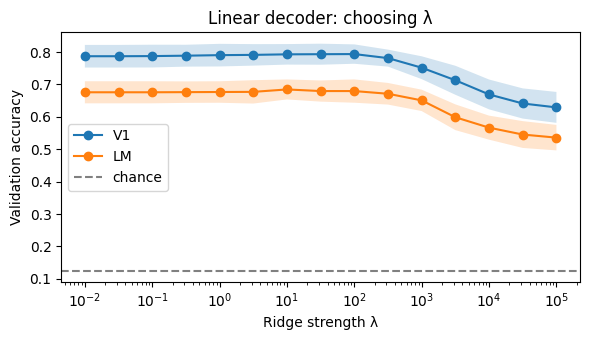

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for area, name in REGIONS.items():
    m, s = val_curves[area].mean(0), val_curves[area].std(0)
    ax.plot(LAMBDAS, m, "o-", label=name)
    ax.fill_between(LAMBDAS, m - s, m + s, alpha=0.2)
ax.axhline(1 / len(directions), color="gray", ls="--", label="chance")
ax.set(xscale="log", xlabel="Ridge strength λ", ylabel="Validation accuracy",
       title="Linear decoder: choosing λ")
ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(out_dir, "linear_lambda_curve.png"), dpi=150)
plt.show()

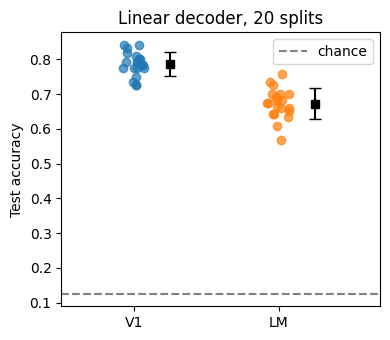

In [8]:
# Test accuracy on each of the 20 splits, per region
fig, ax = plt.subplots(figsize=(4, 3.5))
for i, (area, name) in enumerate(REGIONS.items()):
    acc = results[area]["test_acc"]
    ax.scatter(np.full(len(acc), i) + np.random.uniform(-0.08, 0.08, len(acc)), acc, alpha=0.7)
    ax.errorbar(i + 0.25, acc.mean(), yerr=acc.std(), fmt="ks", capsize=4)
ax.axhline(1 / len(directions), color="gray", ls="--", label="chance")
ax.set(xticks=range(len(REGIONS)), xticklabels=REGIONS.values(), ylabel="Test accuracy",
       title="Linear decoder, 20 splits", xlim=(-0.5, len(REGIONS) - 0.3))
ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(out_dir, "linear_test_accuracy.png"), dpi=150)
plt.show()

## Part 3: interpreting the weights

Left: each unit's **tuning** (its average response to each direction, rescaled per unit so the shapes are comparable).
Right: the decoder's **weights** for that unit, averaged over the 20 splits.
Both use the same unit order: sorted by **preferred direction** (direction with the highest average response,
computed from all trials; this is only for ordering the display).

If the decoder uses each unit to "vote" for the directions it likes, the two images will look alike,
with a diagonal band.

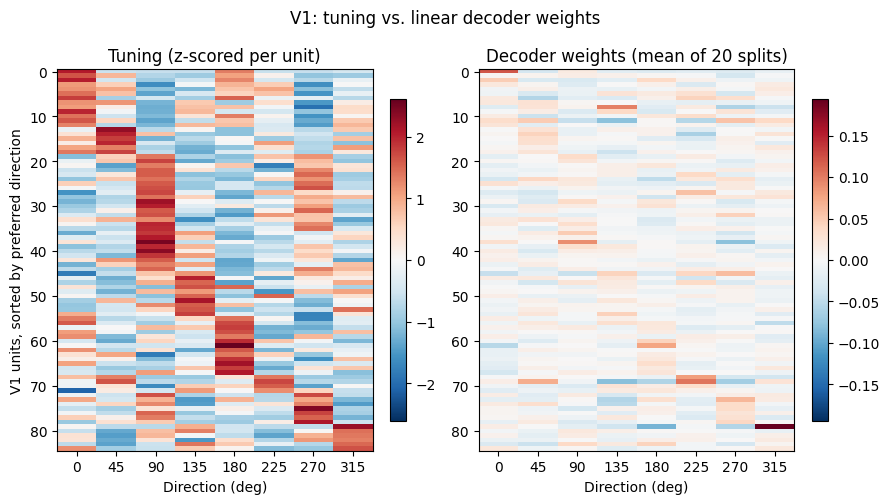

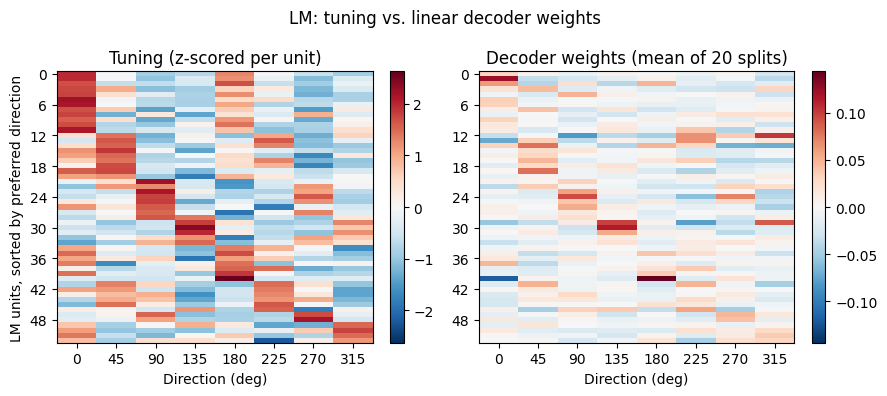

In [9]:
def plot_weights_vs_tuning(area):
    name = REGIONS[area]
    X_raw = shared[f"X_{area}"].astype(float)
    tuning = pd.DataFrame(X_raw).groupby(y).mean().T.values          # units x directions
    order = np.argsort(np.argmax(tuning, axis=1), kind="stable")      # sort by preferred direction
    tz = (tuning - tuning.mean(1, keepdims=True)) / (tuning.std(1, keepdims=True) + 1e-12)
    W = weights[area].mean(axis=0)                                    # units x directions

    fig, axes = plt.subplots(1, 2, figsize=(9, max(4, len(order) * 0.06)))
    for ax, M, title in [(axes[0], tz[order], "Tuning (z-scored per unit)"),
                         (axes[1], W[order], "Decoder weights (mean of 20 splits)")]:
        lim = np.abs(M).max()
        im = ax.imshow(M, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
        ax.set(xticks=range(len(directions)), xticklabels=[f"{d:g}" for d in directions],
               xlabel="Direction (deg)", title=title)
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        fig.colorbar(im, ax=ax, fraction=0.046)
    axes[0].set_ylabel(f"{name} units, sorted by preferred direction")
    fig.suptitle(f"{name}: tuning vs. linear decoder weights")
    fig.tight_layout(); fig.savefig(os.path.join(out_dir, f"linear_weights_{name}.png"), dpi=150)
    plt.show()

for area in REGIONS:
    plot_weights_vs_tuning(area)